<a href="https://colab.research.google.com/github/juyeontech00-hue/TIL/blob/main/Data_Classification_1030_2_ipynb%EC%9D%98_%EC%82%AC%EB%B3%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**데이터와 변수 유형**
<br> 변수의 의미와 저장 자료형을 구분하고, ML에서의 변수의 역할(X와 Y) 이해.

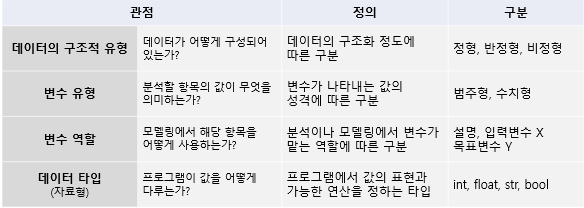

**1. 데이터 유형에 따른 분류**

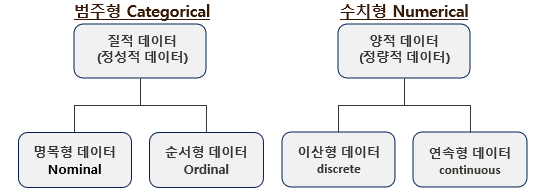

In [ ]:
import pandas as pd

# 예제 데이터프레임 생성
data = {
    'Gender': ['Male', 'Female', 'Female', 'Male'], # 범주형 데이터
    'Age': [23, 29, 31, 22],                        # 수치형 데이터 (이산형)
    'Height': [175.5, 160.2, 162.8, 180.3],         # 수치형 데이터 (연속형)
    'Blood_Type': ['A', 'B', 'O', 'AB'],            # 범주형 데이터 (명목형)
    'Income': [3000, 4000, 3500, 2000]              # 수치형 데이터 (이산형)
}

In [ ]:
import pandas as pd  # 표 형태의 데이터를 다루는 라이브러리
import numpy as np   # 수치 배열과 숫자 계산을 위한 라이브러리
import matplotlib.pyplot as plt  # 그래프를 그리는 라이브러리
from IPython.display import display  # 보기 좋은 출력을 위해...

# pandas version 확인
# 실행 환경에 따라 출력 모양이나 문자열 dtype 표시가 달라질 수 있음
print("pandas version:", pd.__version__)


pandas version: 2.2.3


In [ ]:
## 딕셔너리 (데이터 구조, 자료구조, Data Structure)
 # 키: 열 이름,
 # 각 리스트: 그 열에 들어갈 값

# 모든 리스트의 길이가 같아야... -> 같은 행 수의 표 생성 가능
data = {
    'Gender': ['Male', 'Female', 'Female', 'Male'],  # 명목형: 범주 간 순서 없음
    'Age': [23, 29, 31, 22],                         # 만 나이를 정수 년으로 기록한 값
    'Height': [175.5, 160.2, 162.8, 180.3],          # 연속형 측정값, 단위 cm
    'Blood_Type': ['A', 'B', 'O', 'AB'],             # 명목형: 혈액형
    'Income': [3000, 4000, 3500, 2000]               # 소득 금액: 단위가 지정되지 않은 값
}


In [ ]:
# 위 데이터를 people_df라는 이름(변수명)으로 관리.
people_df = pd.DataFrame(data)
display(people_df)

,Gender,Age,Height,Blood_Type,Income
0,Male,23,175.5,A,3000
1,Female,29,160.2,B,4000
2,Female,31,162.8,O,3500
3,Male,22,180.3,AB,2000


**결과 해석**

행 4개는 사람 4명, 열 5개는 각 사람의 특성 5개 <br> 제일 왼쪽의 0~3 숫자는 pandas가 붙인 행 라벨(index)

| 변수 | 의미에 따른 해석 | 기타 |
|---|---|---|
| Gender | 범주형·명목형 | 범주 2개(male, female) |
| Age | 만 나이를 정수 년으로 기록한 이산적인 값 | 연속형인 경우? |
| Height | 수치형·연속형 | 소수 한 자리로 관리 <- 측정 정밀도 |
| Blood_Type | 범주형·명목형 | A, B, O, AB 사이에 크기 순서 의미 없음 |
| Income | 수치형 금액 | 최소 화폐 단위로 적용 <- 이산적 `int`라는 자료형 만으로 판단 X |

데이터에 소득의 통화, 기간이 명시되어 있지 않음 <br>
임의로 ‘만원’이나 ‘월 소득’으로 해석 X <br>
실제 데이터 분석 시 단위 확인 필수 !!!


In [ ]:
# people_df

In [ ]:
# dtypes : 각 열의 데이터 타입 확인
print(people_df.dtypes)



Gender         object
Age             int64
Height        float64
Blood_Type     object
Income          int64
dtype: object


**결과 해석**<br>
pandas가 열에 들어 있는 값들을 보고 정수형, 실수형등으로 자료형 구성
<br>

- Age, Income:  보통 `int64`로 표시
- Height: `float64`로 표시.
- Gender, Blood_Type: pandas 버전과 설정에 따라 `object` 또는 `str` 등으로 표시.
- `object` 문자열 + 여러 종류의 Python 객체를 담을 수 있는 자료형 <br>
- 출력 마지막의 `dtype: ...`는 **자료형 목록 자체를 담은 Series의 dtype**입니다. (원본 표의 모든 열이 그 타입이라는 뜻이 아님.

**dtypes는 명목형·서열형·이산형·연속형을 자동으로 판정해 주지 않음.**

In [ ]:
# 숫자 자료형 열의 기초 통계량 계산
people_df.describe()

,Age,Height,Income
count,4.000000,4.000000,4.000000
mean,26.250000,169.700000,3125.000000
std,4.425306,9.727281,853.912564
min,22.000000,160.200000,2000.000000
25%,22.750000,162.150000,2750.000000
50%,26.000000,169.150000,3250.000000
75%,29.500000,176.700000,3625.000000
max,31.000000,180.300000,4000.000000


In [ ]:
people_df.describe().round(2)

,Age,Height,Income
count,4.00,4.00,4.00
mean,26.25,169.70,3125.00
std,4.43,9.73,853.91
min,22.00,160.20,2000.00
25%,22.75,162.15,2750.00
50%,26.00,169.15,3250.00
75%,29.50,176.70,3625.00
max,31.00,180.30,4000.00


count : 결측값을 제외한 값의 개수 <br>
mean : 평균 <br>
std : 표본표준편차: 평균 주변의 퍼짐<br>
min / max : 최솟값 / 최댓값 <br>
25% / 50% / 75% : 1사분위수 / 중앙값 / 3사분위수

위 데이터의 평균,  나이 26.25세, 키 169.70cm, 소득 3125.00

**2. 파이썬의 기본 자료형**

In [ ]:
# 파이썬 기본 데이터 타입 예제
# 변수 이름에 서로 다른 종류의 값을 할당(연결)
int_var = 10            # int (정수형)
float_var = 10.5        # float (실수형)
str_var = 'Python'      # str (문자열)
bool_var = True         # bool (불리언) 참/거짓, True 또는 False

# 각 변수의 데이터 타입 확인
print(f"int_var: {type(int_var)}")
print(f"float_var: {type(float_var)}")
print(f"str_var: {type(str_var)}")
print(f"bool_var: {type(bool_var)}")


int_var: <class 'int'>
float_var: <class 'float'>
str_var: <class 'str'>
bool_var: <class 'bool'>


**3. 단변량(Univariate) 분석 - 파일 불러오기**

In [ ]:
import pandas as pd

df=pd.read_csv('/content/Age_and_Income_Dataset.csv')
df

,age,income,job_type,education_level,work_experience,marital_status
0,25,3000,Engineer,Bachelor,3,Single
1,32,4500,Teacher,Master,7,Married
2,40,6000,Doctor,PhD,15,Married
3,50,7500,Manager,PhD,20,Married
4,28,3200,Designer,Bachelor,5,Single
5,36,5000,Sales,Bachelor,10,Single
6,45,6700,Lawyer,Master,18,Married
7,52,7200,Manager,PhD,25,Married
8,60,8000,Retired,NaN,40,Widowed
9,22,2900,Student,Bachelor,1,Single


In [ ]:
# df.describe()

Age Statistics:
count    10.000000
mean     39.000000
std      12.613925
min      22.000000
25%      29.000000
50%      38.000000
75%      48.750000
max      60.000000
Name: age, dtype: float64


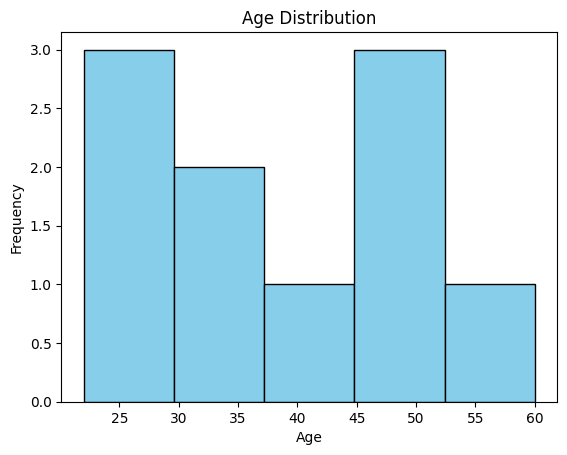

In [ ]:
import matplotlib.pyplot as plt

# 나이 변수에 대한 기초 통계량 계산
print("Age Statistics:")
print(df['age'].describe())

# 히스토그램 그리기
plt.hist(df['age'], bins=5, color='skyblue', edgecolor='black')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()


**4. 다변량(Multivariate) 분석**

In [ ]:
# 나이와 수입 간의 상관관계 계산
correlation = df['age'].corr(df['income'])
print(f"Correlation between Age and Income: {correlation}")

# 산점도 그리기
plt.scatter(df['age'], df['income'], color='green')
plt.title('Age vs Income')
plt.xlabel('Age')
plt.ylabel('Income')
plt.show()


NameError: name 'df' is not defined

**5. 변수 분류** <Br><Br>
종속 변수와 독립 변수

In [ ]:
from sklearn.linear_model import LinearRegression
import numpy as np

# 종속 변수 (Income)와 독립 변수 (Age) 설정
y = df['income'].values  # 종속 변수

X = df[['age']].values   # 독립 변수


# 선형 회귀 모델 훈련
model = LinearRegression()
model.fit(X, y)

# 예측 및 시각화
predicted_income = model.predict(X)

plt.scatter(X, y, color='blue', label='Actual Income')
plt.plot(X, predicted_income, color='red', label='Predicted Income')
plt.title('Income vs Age with Linear Regression')
plt.xlabel('Age')
plt.ylabel('Income')
plt.legend()
plt.show()

# 모델의 기울기와 절편 출력
print(f"Model Slope (Coefficient): {model.coef_[0]}")
print(f"Model Intercept: {model.intercept_}")

# model.coef model.intercept_ 기울기,절편

NameError: name 'df' is not defined